# Dania et al. (2024): a Paul-trapped nanoparticle with an ultrahigh quality factor

L. Dania, D. S. Bykov, F. Goschin, M. Teller, A. Kassid and T. E. Northup, *Ultrahigh quality factor of a
levitated nanomechanical oscillator*, Phys. Rev. Lett. **132**, 133602 (2024),
[doi:10.1103/PhysRevLett.132.133602](https://doi.org/10.1103/PhysRevLett.132.133602) (open version:
arXiv:2304.02408).

A charged silica nanoparticle is held in a linear Paul trap in ultrahigh vacuum and its motion along
the trap axis, confined by the dc endcaps, is studied by ring-down and ring-up measurements. The paper
reports the axial frequency, the damping rate against pressure, a quality factor above 10¹⁰ and a heating
rate it attributes, if electrical, to electrode voltage noise of 38 nV/√Hz.

This notebook builds the particle and a linear `PaulTrap` (`PaulTrap.linear`) and compares

1. the axial secular frequency and the trap's stability,
2. the electrode-noise chain $S_v \to S_{EE} \to S_{ff} \to$ heating rate (the paper's numbers),
3. the gas damping coefficient and gas heating rate with levisim's gas model,
4. a stochastic simulation with the full rf force and the electrode noise: secular frequencies,
   micromotion, and the heating rate of the axial motion.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| charge, mass | $q$ = +300 e, $m$ = 4.3 × 10⁻¹⁷ kg | main text (the mass is twice that of a 300 nm sphere: probably a cluster of two) |
| particle | silica sphere of that mass (levisim's default silica, 1850 kg/m³, radius 177 nm) | **assumed** shape |
| axial frequency $\Omega_z/2\pi$ | 1.28 kHz, from dc endcaps | main text ("for which DC voltages provide confinement") |
| particle-electrode distance | $d$ = 0.92 mm | main text (heating-rate paragraph) |
| electrode voltage noise | $S_v$ = 38 nV/√Hz (inferred by the paper from the measured heating) | main text |
| measured heating rates | 3.3(2) × 10⁴ phonon/s (continuous light), 3.1(8) × 10⁴ (dark) | main text, Fig. 4b |
| damping | $\gamma/2\pi = aP$, $a$ = 0.9(2) kHz/mbar; $\gamma_{P4}/2\pi$ = 69(22) nHz at 7 × 10⁻¹¹ mbar | Fig. 3a, abstract |
| rf drive | **not stated** in this paper: $\Omega_\mathrm{rf}/2\pi$ = 10 kHz, $r_0$ = 0.92 mm, $V_\mathrm{rf}$ chosen for $q$ = 0.4 | illustrative |
| endcaps | $z_0$ = 2 mm, $U_\mathrm{endcap}$ chosen for $\Omega_z/2\pi$ = 1.28 kHz | illustrative |

In the real trap the axial frequency also depends on the rf ($\Omega_z$ changes with $V_d/\Omega_d^2$,
Appendix J), i.e. the rf field has an axial component; the ideal linear trap here has none.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from levisim.core.constants import kB, ħ
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import Hz, kHz, mbar, mm, nm
from levisim.physics.fields import PaulTrap
from levisim.physics.gas import Gas
from levisim.physics.materials import LEVISIM_DEFAULT_SILICA
from levisim.physics.particle import Sphere
from levisim.physics.trap import Trap
from levisim.simulation import FreeSpaceSimulation

set_plt_rcParams_to_xmgrace_style()
T_START = time.time()
T0 = 293.0

## 1. The particle and the trap

In [2]:
m_paper = 4.3e-17
r = (3 * m_paper / (4*np.pi*LEVISIM_DEFAULT_SILICA.ρ))**(1/3)
particle = Sphere(r=r, charge=300)
Ω_rf, r0, z0 = 10*kHz, 0.92*mm, 2*mm
Ωz_paper = 1.28*kHz
V_rf = 0.4 * particle.m * r0**2 * Ω_rf**2 / (2 * particle.q)       # q = 0.4 radially
U_endcap = particle.m * z0**2 * Ωz_paper**2 / particle.q             # Ωz² = Q U/(m z0²)
S_v = (38e-9)**2                                                      # V²/Hz, one-sided
paul = PaulTrap.linear(V_rf, Ω_rf, r0=r0, U_endcap=U_endcap, z0=z0, voltage_noise_psd=S_v, noise_distances=0.92*mm)
print(f'radius {r/nm:.0f} nm, m = {particle.m:.3e} kg; V_rf = {V_rf:.0f} V, U_endcap = {U_endcap:.3f} V')
print(paul.report_str(particle))

radius 177 nm, m = 4.300e-17 kg; V_rf = 598 V, U_endcap = 231.460 V
PaulTrap(V_rf=597.864 V, Ω_rf/2π=10000 Hz, r0=0.00092 m, U_dc=231.46 V, geometry=[1.0, -1.0, 0.0], dc_geometry=[-0.5, -0.5, 1.0], κ_geom=1, centre=[0.0, 0.0, 0.0] m)
  particle charge = 300 e, mass = 4.3000e-17 kg
  x: a = -0.032768, q = +0.4, stable = True, Ω/2π = 1.08665 (lowest), 1.11516 (next), 1.1156 (exact) kHz
  y: a = -0.032768, q = -0.4, stable = True, Ω/2π = 1.08665 (lowest), 1.11516 (next), 1.1156 (exact) kHz
  z: a = +0.065536, q = +0, stable = True, Ω/2π = 1.28 (lowest), 1.28 (next), 1.28 (exact) kHz
  trap depth = 5295 eV


The endcaps defocus radially ($a_{x,y} = -a_z/2$), which lowers the radial secular frequencies from
the rf-only value; all three axes are in the first stability region.

## 2. Electrode noise and the heating rate

The paper converts the measured heating rate to a white force noise $S_{ff} = 4m\hbar\Omega_z\Gamma$ and
then, if the noise is electrical, to a field noise $S_{EE} = S_{ff}/q^2$ and a voltage noise
$S_v = d\sqrt{S_{EE}}$. `PaulTrap` takes the chain in the forward direction: `voltage_noise_psd` and
`noise_distances` give $S_{EE}$ (`electric_field_noise_psd`), the two-sided force noise for the
simulation (`noise`), and the heating rate $\Gamma = q^2 S_{EE}/(4m\hbar\Omega)$ (`heating_rate`).

In [3]:
S_EE = paul.electric_field_noise_psd()[2]
S_ff = particle.q**2 * S_EE
Γ_el = paul.heating_rate(particle, Ω=Ωz_paper)[2]
print(f'S_EE = {S_EE:.3g} (V/m)²/Hz   (paper 1.7e-9)')
print(f'S_ff = {S_ff:.3g} N²/Hz        (paper 4e-42)')
print(f'heating rate = {Γ_el:.3g} phonon/s (measured 3.3(2)e4 continuous, 3.1(8)e4 dark)')
for Γ_meas in (3.3e4, 3.1e4):
    print(f'  S_ff implied by {Γ_meas:.2g} phonon/s: 4 m ħ Ωz Γ = {4*particle.m*ħ*Ωz_paper*Γ_meas:.3g} N²/Hz')
S_v_threshold = (10e-9)**2
print(f'at the 10 nV/√Hz threshold: {Γ_el * S_v_threshold / S_v:.3g} phonon/s')

S_EE = 1.71e-09 (V/m)²/Hz   (paper 1.7e-9)
S_ff = 3.94e-42 N²/Hz        (paper 4e-42)
heating rate = 2.7e+04 phonon/s (measured 3.3(2)e4 continuous, 3.1(8)e4 dark)
  S_ff implied by 3.3e+04 phonon/s: 4 m ħ Ωz Γ = 4.81e-42 N²/Hz
  S_ff implied by 3.1e+04 phonon/s: 4 m ħ Ωz Γ = 4.52e-42 N²/Hz
at the 10 nV/√Hz threshold: 1.87e+03 phonon/s


From 38 nV/√Hz levisim gets $S_{EE}$ = 1.71 × 10⁻⁹ (V/m)²/Hz and $S_{ff}$ = 3.9 × 10⁻⁴² N²/Hz, the paper's
values, and a heating rate of 2.7 × 10⁴ phonon/s, inside the 1σ range of the dark measurement and 18 %
below the continuous one. The paper's chain is rounded: its measured rates imply $S_{ff}$ = 4.5-4.8 ×
10⁻⁴², which it quotes as 4 × 10⁻⁴², and the 38 nV/√Hz follows from the rounded value. For the same reason,
at the 10 nV/√Hz "threshold" levisim gives 1.9 × 10³ phonon/s, just below the gas heating rate of
2.1 × 10³, where the paper (scaling its measured rate) says "slightly larger than Γ_gas".

## 3. Gas damping and gas heating

In [4]:
amu = 1.66054e-27
print(f'{"gas":>10} {"a = γ/(2πP) [kHz/mbar]":>24}')
for name, m_gas in (('H₂', 2.016*amu), ('N₂', 28.013*amu)):
    trap = Trap(fields=[paul], particle=particle, gas=Gas(P=1e-4*mbar, T=T0, m=m_gas))
    print(f'{name:>10} {trap.Γz/Hz/1e-4/1e3:24.3f}')
print(f'{"measured":>10} {"0.9(2)":>24}')

γ_P4 = 69e-9*Hz
print(f'\nQ = Ωz/γ at 7e-11 mbar from the measured γ: {Ωz_paper/γ_P4:.3g} (paper 1.8(6)e10)')
print(f'gas heating k_B T γ/(ħ Ωz) from the measured γ: {kB*T0*γ_P4/(ħ*Ωz_paper):.3g} phonon/s (paper 2.1e3)')
trap_P4 = Trap(fields=[paul], particle=particle, gas=Gas(P=7e-11*mbar, T=T0, m=2.016*amu))
print(f"levisim's H₂ damping at 7e-11 mbar: γ/2π = {trap_P4.Γz/Hz*1e9:.1f} nHz, Q = {trap_P4.Qz:.3g}")

       gas   a = γ/(2πP) [kHz/mbar]
        H₂                    0.098
        N₂                    0.366
  measured                   0.9(2)

Q = Ωz/γ at 7e-11 mbar from the measured γ: 1.86e+10 (paper 1.8(6)e10)
gas heating k_B T γ/(ħ Ωz) from the measured γ: 2.07e+03 phonon/s (paper 2.1e3)
levisim's H₂ damping at 7e-11 mbar: γ/2π = 6.9 nHz, Q = 1.86e+11


levisim's free-molecular (Epstein) damping of a sphere of this mass is 0.10 kHz/mbar in hydrogen and
0.37 kHz/mbar in nitrogen, 2.4-9 times below the measured 0.9(2) kHz/mbar. The paper finds the same kind
of gap with its own model and states that reasonable assumptions about gas composition and temperature
cannot alone explain it (Appendix I); a cluster of two spheres has a larger surface per mass than the
sphere assumed here, and the gauge calibration depends on the gas species. With the measured $\gamma$, the
quality factor and gas heating rate follow the paper's numbers exactly (both are definitions).

## 4. Time domain: secular motion, micromotion and electrode-noise heating

The simulation integrates the full rf force at ultrahigh vacuum with the electrode noise switched on
(`noise_in_simulation`, the default). Started at rest, the mean energy of the axial motion grows at
$\hbar\Omega_z\Gamma = q^2 S_{EE}/(4m)$, independent of the frequency; eight seeds of 0.2 s each give the
ensemble mean.

mean axial heating: 2.1e-26 J/s = 2.47e+04 phonon/s; expected q² S_EE/(4m) = 2.29e-26 J/s = 2.7e+04 phonon/s
ratio 0.91; for 8 independent linear random walks the 1σ scatter of the slope is ~0.35
secular peaks (last run): x 1115 Hz (Floquet 1116), z 1280 Hz (paper 1280); bin 5 Hz


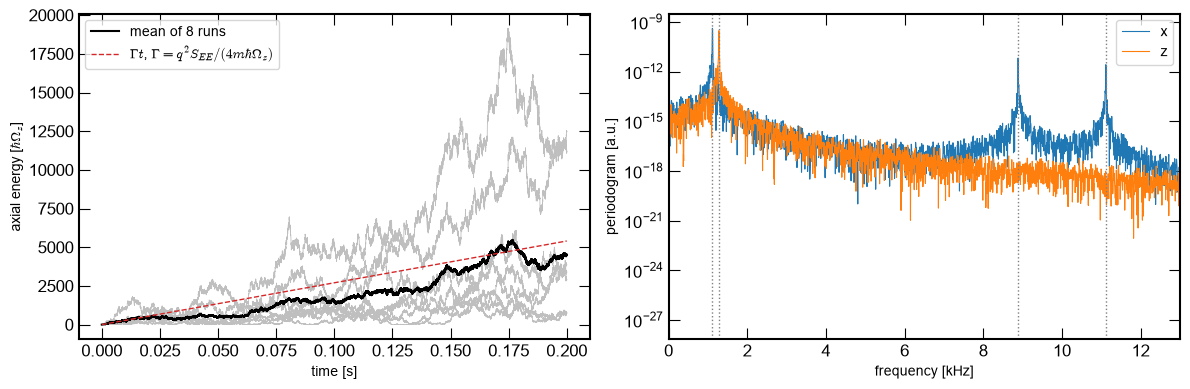

In [5]:
trap = Trap(fields=[paul], particle=particle, gas=Gas(P=7e-11*mbar, T=T0, m=2.016*amu))
Δt = 1 / (40 * Ω_rf / Hz)
N = 80_000
energies = []
for seed in range(8):
    sim = FreeSpaceSimulation(trap=trap, num_samples=N, Δt=Δt, seed=seed, zero_mean=False, store_momenta=True)
    z, pz = sim.z.values, sim.pz.values
    energies.append(0.5*pz**2/particle.m + 0.5*particle.m*Ωz_paper**2*z**2)
energies = np.array(energies)
t = np.arange(N + 1) * Δt
slope = np.polyfit(t, energies.mean(axis=0), 1)[0]
expected = particle.q**2 * S_EE / (4*particle.m)
print(f'mean axial heating: {slope:.3g} J/s = {slope/(ħ*Ωz_paper):.3g} phonon/s; '
      f'expected q² S_EE/(4m) = {expected:.3g} J/s = {Γ_el:.3g} phonon/s')
print(f'ratio {slope/expected:.2f}; for 8 independent linear random walks the 1σ scatter of the slope is ~{1/np.sqrt(8):.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t, energies.T/(ħ*Ωz_paper), color='0.75', lw=0.6)
ax1.plot(t, energies.mean(axis=0)/(ħ*Ωz_paper), 'k', lw=1.5, label='mean of 8 runs')
ax1.plot(t, Γ_el*t, 'C3--', label=r'$\Gamma t$, $\Gamma = q^2 S_{EE}/(4m\hbar\Omega_z)$')
ax1.set_xlabel('time [s]'); ax1.set_ylabel(r'axial energy [$\hbar\Omega_z$]'); ax1.legend()

x = sim.x.values - sim.x.values.mean()
f = np.fft.rfftfreq(len(x), Δt)
for label, values, colour in (('x', x, 'C0'), ('z', sim.z.values - sim.z.values.mean(), 'C1')):
    ax2.semilogy(f/1e3, np.abs(np.fft.rfft(values*np.hanning(len(values))))**2, colour, lw=0.8, label=label)
Ω_sec = paul.secular_frequencies(particle, 'exact')
for f0 in (Ω_sec[0]/Hz, Ωz_paper/Hz, Ω_rf/Hz - Ω_sec[0]/Hz, Ω_rf/Hz + Ω_sec[0]/Hz):
    ax2.axvline(f0/1e3, color='0.5', ls=':', lw=1)
ax2.set_xlim(0, 13); ax2.set_xlabel('frequency [kHz]'); ax2.set_ylabel('periodogram [a.u.]'); ax2.legend()
fig.tight_layout()

def peak(values, lo, hi):
    spectrum = np.abs(np.fft.rfft((values - values.mean())*np.hanning(len(values))))**2
    band = np.flatnonzero((f > lo) & (f < hi))
    return f[band[np.argmax(spectrum[band])]]
print(f'secular peaks (last run): x {peak(sim.x.values, 300, 3000):.0f} Hz (Floquet {Ω_sec[0]/Hz:.0f}), '
      f'z {peak(sim.z.values, 300, 3000):.0f} Hz (paper 1280); bin {f[1]:.0f} Hz')

The simulated axial heating agrees with the rate from the electrode-noise formula within the
scatter of eight runs, so the noise that `PaulTrap` injects into `FreeSpaceSimulation` is the one its
`heating_rate` assumes. The radial spectrum shows the secular frequency and the micromotion sidebands at
$\Omega_\mathrm{rf} \mp \Omega_x$.

## Summary

| Quantity | levisim | Paper |
|---|---|---|
| $\Omega_z/2\pi$ | 1.28 kHz (endcap voltage set to it; exact = pseudopotential on a dc axis) | 1.28 kHz |
| $S_{EE}$, $S_{ff}$ from 38 nV/√Hz at 0.92 mm | 1.71 × 10⁻⁹ (V/m)²/Hz, 3.9 × 10⁻⁴² N²/Hz | 1.7 × 10⁻⁹, 4 × 10⁻⁴² |
| electrode-noise heating | 2.7 × 10⁴ phonon/s | 3.1(8) × 10⁴ (dark), 3.3(2) × 10⁴ (continuous) |
| gas damping coefficient $a$ | 0.10 (H₂), 0.37 (N₂) kHz/mbar for a sphere of the measured mass | 0.9(2) kHz/mbar (measured); the paper's own model also falls short |
| $Q$, gas heating from the measured γ | 1.86 × 10¹⁰, 2.1 × 10³ phonon/s | 1.8(6) × 10¹⁰, 2.1 × 10³ |
| simulated axial heating (8 runs, full rf force) | 0.91 × the formula's rate (1σ scatter of 8 runs ≈ 0.35) | — |

The rf drive and the endcap geometry are illustrative (not given in the paper), so the radial frequencies
are not a comparison.

In [6]:
print(f'runtime {time.time() - T_START:.0f} s')

runtime 36 s
